# Filtered (causal) regime probabilities + confidence-weighted risk

**Why this notebook exists.** `macro-regime` / `micro-regime` label days with Viterbi (`model.predict`) from an HMM fit on the *whole* history. Each label therefore uses future data, so per-regime statistics are hindsight descriptions, not something you could have known on the day.

**Design (declared before looking at results):**

| Choice | Setting |
|---|---|
| Signal | **Filtered** `P(state_t given x_1..x_t)` via the forward pass only (own implementation, unit-tested against hmmlearn) |
| Parameters | Expanding-window walk-forward: 3y warm-up, refit every 6m; scaler + HMM see only past data |
| Features | `ret_5d`, `log_rv_20d`, `log_vix`, `vix_chg_5d` (all causal) |
| Model | 3 states, diagonal covariance (~29 params vs 299/425 before), best of 10 restarts |
| State identity | ordered calm -> stressed by training-window return volatility (labels are not stable across refits) |
| Use of the signal | **soft** exposure = sum_k p_k * min(1, target_vol / vol_k); target vol 12%, long-only, cash earns 6%, 5 bps cost, signal at close *t* traded at close *t+1* |
| Benchmarks | buy & hold; plain trailing-vol targeting with **no HMM** (the real test of whether the HMM adds anything) |

Caveats: Nifty is a *price* index (no dividends, ~1.3%/yr), there is no tradable-instrument tracking error, and the sample is ~6.6 years.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf

pd.set_option("display.width", 160)
CFG = rf.WFConfig(n_states=3, cov_type="diag", warmup_days=756, refit_days=126, n_init=10, seed=42)
TARGET_VOL, RF, COST_BPS = 0.12, 0.06, 5.0

df = rf.load_data()
feats = rf.build_features(df)
ret = df["close"].pct_change().reindex(feats.index)
print(f"Raw data {df.index.min().date()} -> {df.index.max().date()} ({len(df)} rows); features from {feats.index.min().date()} ({len(feats)} rows)")
feats.describe().T[["mean", "std", "min", "max"]]

Raw data 2019-01-02 -> 2025-08-21 (1635 rows); features from 2019-01-30 (1615 rows)


,mean,std,min,max
ret_5d,0.002602,0.025065,-0.211017,0.100046
log_rv_20d,-4.761026,0.430060,-5.756954,-2.864700
log_vix,2.817493,0.307906,2.315995,4.426133
vix_chg_5d,-0.001292,0.117401,-0.559906,0.831165


## 1. Walk-forward filtered probabilities

Out-of-sample: 2022-02-24 -> 2025-08-21  (859 days, 7 refits)

State return-vol (annualised) estimated on each fold's TRAIN window:
      S0     S1     S2
0  0.111  0.179  0.524
1  0.111  0.183  0.479
2  0.112  0.178  0.473
3  0.106  0.176  0.472
4  0.107  0.174  0.470
5  0.101  0.167  0.425
6  0.110  0.175  0.435


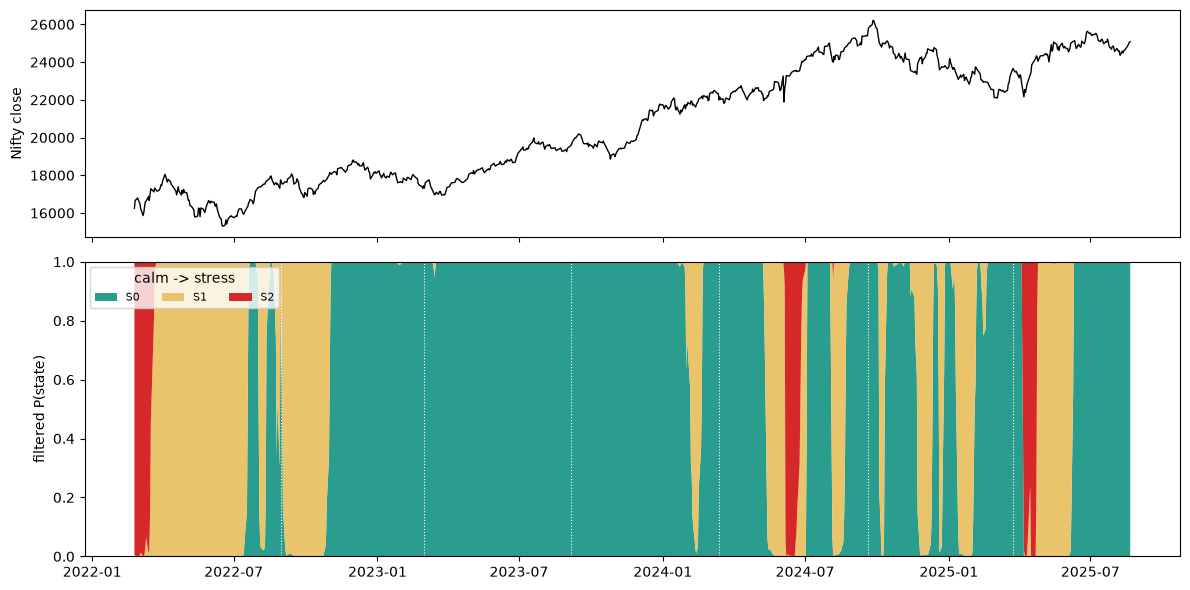

In [2]:
res = rf.walk_forward(feats, ret, CFG)
P, VOL = res.probs, res.state_vol
oret = ret.reindex(P.index)
print(f"Out-of-sample: {P.index.min().date()} -> {P.index.max().date()}  ({len(P)} days, {res.fold_id.nunique()} refits)")
print("\nState return-vol (annualised) estimated on each fold's TRAIN window:")
print(VOL.groupby(res.fold_id).first().round(3))

cols = ["#2a9d8f", "#e9c46a", "#d62828"]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax[0].plot(df["close"].reindex(P.index), color="black", lw=1)
ax[0].set_ylabel("Nifty close")
ax[1].stackplot(P.index, P.T.values, colors=cols[:P.shape[1]], labels=[f"S{k}" for k in range(P.shape[1])])
ax[1].set_ylim(0, 1); ax[1].set_ylabel("filtered P(state)"); ax[1].legend(loc="upper left", ncol=3, fontsize=8, title="calm -> stress")
for f in res.fold_id.drop_duplicates().index[1:]:
    ax[1].axvline(f, color="white", lw=0.8, ls=":")
plt.tight_layout(); plt.show()

## 2. How many states? Out-of-sample *predictive* likelihood

Mean one-step-ahead log-density of each OOS day under the filter. This replaces in-sample AIC/BIC, which fell monotonically in the old notebooks. Caveat: it measures how well the Gaussian mixture explains the features, **not** whether a trading rule built on it makes money, so it is reported but not used to tune the strategy.

In [3]:
rows = []
for n in (2, 3, 4, 5):
    r = rf.walk_forward(feats, ret, rf.WFConfig(n_states=n, cov_type="diag", n_init=10))
    k = (n - 1) + n * (n - 1) + n * feats.shape[1] * 2
    rows.append({"n_states": n, "free_params": k, "OOS_LL_per_day": r.oos_ll.mean()})
pd.DataFrame(rows).set_index("n_states").round(3)

,free_params,OOS_LL_per_day
n_states,,
2,19,-4.265
3,32,-4.022
4,47,-3.775
5,64,-3.583


## 3. Are these regimes real? Persistence, certainty, hindsight gap

* **Expected duration** `1/(1-p_ii)` from the last fold's transition matrix: a "regime" lasting 2 days is noise.
* **Entropy** of the filtered vector (0 = certain, 1 = uniform): genuine switches should show as uncertainty spikes, not instant flips.
* **Filtered vs smoothed** argmax agreement: the gap is how much hindsight the old Viterbi labels were using.

Last-fold transition matrix (rows = from, calm -> stress):
       S0     S1     S2
S0  0.991  0.009  0.000
S1  0.011  0.982  0.007
S2  0.008  0.026  0.966

Expected duration (days):
S0    116.4
S1     54.6
S2     29.0
Name: expected_days, dtype: float64

Realised OOS runs of the argmax-filtered state:
       count  mean  median  max
state                          
S0        13  44.2    21.0  311
S1        14  17.6    11.0   83
S2         3  12.3    12.0   15

Mean entropy 0.057; share of days with max-prob < 0.6: 1.7%
Filtered vs smoothed argmax agreement: 93.5%  -> 6.5% of days would be labelled differently with hindsight


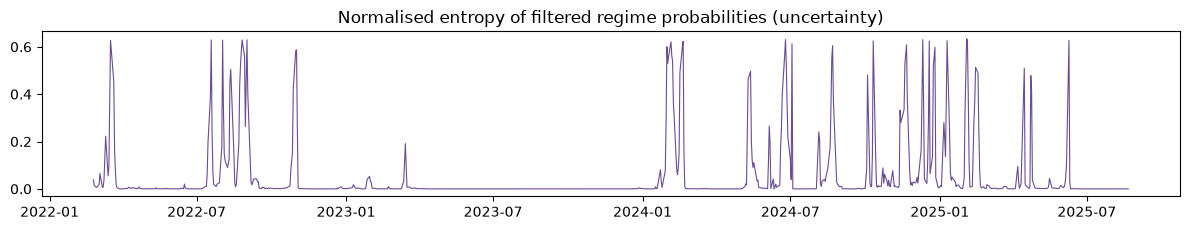

In [4]:
T = res.transmats[-1]
dur = pd.Series(1 / (1 - np.diag(T)), index=P.columns, name="expected_days")
print("Last-fold transition matrix (rows = from, calm -> stress):"); print(pd.DataFrame(T, index=P.columns, columns=P.columns).round(3))
print("\nExpected duration (days):"); print(dur.round(1))

hard = P.idxmax(axis=1)
runs = rf.run_lengths(hard)
print("\nRealised OOS runs of the argmax-filtered state:")
print(runs.groupby("state")["duration"].agg(["count", "mean", "median", "max"]).round(1))

H = rf.entropy(P)
print(f"\nMean entropy {H.mean():.3f}; share of days with max-prob < 0.6: {(P.max(axis=1) < 0.6).mean():.1%}")
agree = (hard == res.smoothed.idxmax(axis=1)).mean()
print(f"Filtered vs smoothed argmax agreement: {agree:.1%}  -> {1-agree:.1%} of days would be labelled differently with hindsight")

fig, ax = plt.subplots(figsize=(12, 2.4)); ax.plot(H, color="#6a4c93", lw=0.8)
ax.set_title("Normalised entropy of filtered regime probabilities (uncertainty)"); plt.tight_layout(); plt.show()

## 4. Does confidence-weighted risk work? (the actual test)

All strategies are long-only Nifty / cash, with identical costs, rf and one-day execution lag. **VolTarget (no HMM)** uses only trailing 20d realised vol. If the HMM can't beat it, the regime machinery isn't earning its complexity.

In [5]:
def run_all(P, VOL, oret, feats, target=TARGET_VOL, ema_span=1):
    Ps = rf.ema_probs(P, ema_span)
    expo = {
        "HMM soft": rf.soft_exposure(Ps, VOL, target),
        "HMM hard (argmax)": rf.soft_exposure(Ps, VOL, target, hard=True),
        "VolTarget (no HMM)": rf.vol_target_exposure(feats, P.index, target),
        "Buy & hold": pd.Series(1.0, index=P.index),
    }
    rets = {k: rf.backtest(oret, v, RF, COST_BPS) for k, v in expo.items()}
    return expo, rets

expo, rets = run_all(P, VOL, oret, feats)
table = pd.DataFrame({k: rf.perf(rets[k], expo[k], RF) for k in rets})
table.round(3)

,HMM soft,HMM hard (argmax),VolTarget (no HMM),Buy & hold
CAGR,0.078,0.077,0.101,0.128
AnnVol,0.111,0.111,0.114,0.134
Sharpe,0.205,0.196,0.390,0.529
Sortino,0.282,0.270,0.548,0.753
MaxDD,-0.167,-0.167,-0.153,-0.158
Calmar,0.464,0.460,0.662,0.811
AvgExposure,0.876,0.877,0.889,1.000
AnnTurnover,2.878,2.915,3.258,0.000


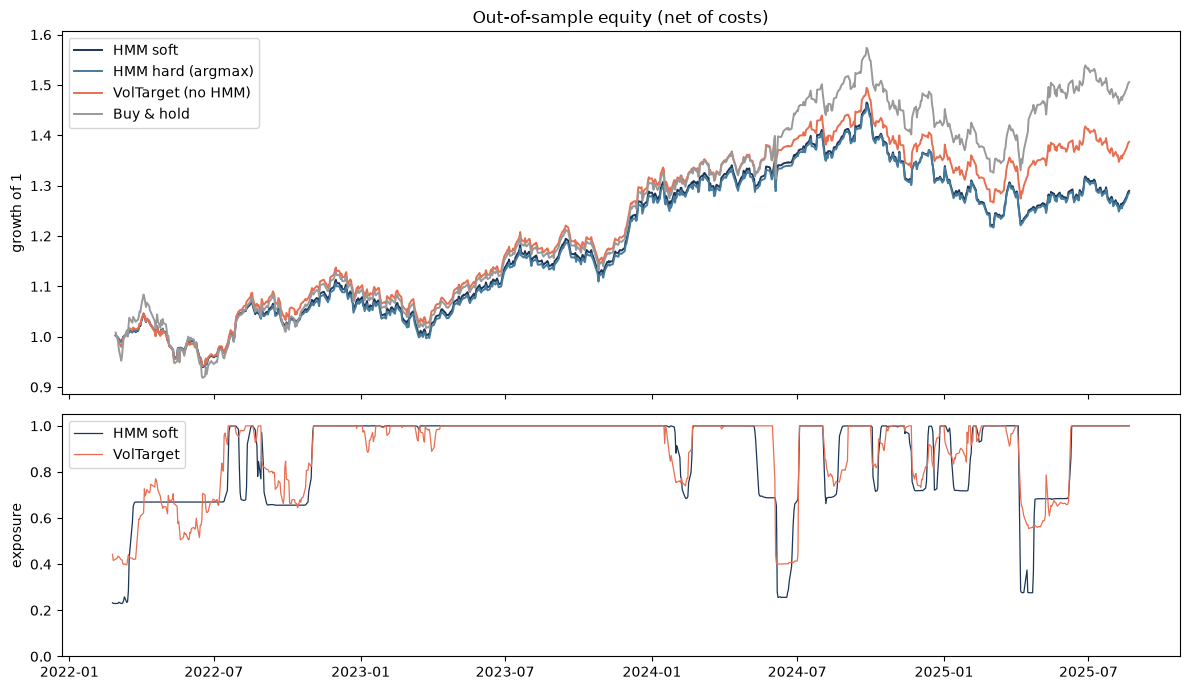

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
for k, c in zip(rets, ["#1d3557", "#457b9d", "#e76f51", "#999999"]):
    ax[0].plot((1 + rets[k]).cumprod(), label=k, color=c, lw=1.4)
ax[0].set_ylabel("growth of 1"); ax[0].legend(); ax[0].set_title("Out-of-sample equity (net of costs)")
ax[1].plot(expo["HMM soft"], color="#1d3557", lw=0.9, label="HMM soft")
ax[1].plot(expo["VolTarget (no HMM)"], color="#e76f51", lw=0.9, label="VolTarget")
ax[1].set_ylabel("exposure"); ax[1].set_ylim(0, 1.05); ax[1].legend()
plt.tight_layout(); plt.show()

### Is any difference distinguishable from noise?

Paired moving-block bootstrap (20-day blocks) of the Sharpe-ratio **difference**. With ~3.5 years of daily data, Sharpe standard errors are large, so treat point estimates with suspicion.

In [7]:
out = []
for a, b in [("HMM soft", "VolTarget (no HMM)"), ("HMM soft", "Buy & hold"), ("VolTarget (no HMM)", "Buy & hold")]:
    pt, lo, hi, p = rf.block_bootstrap_sharpe_diff(rets[a], rets[b], RF)
    out.append({"A": a, "B": b, "Sharpe(A)-Sharpe(B)": pt, "95% CI lo": lo, "95% CI hi": hi, "P(diff<=0)": p})
pd.DataFrame(out).round(3)

,A,B,Sharpe(A)-Sharpe(B),95% CI lo,95% CI hi,P(diff<=0)
0,HMM soft,VolTarget (no HMM),-0.185,-0.383,-0.033,0.992
1,HMM soft,Buy & hold,-0.325,-0.702,-0.022,0.982
2,VolTarget (no HMM),Buy & hold,-0.140,-0.412,0.102,0.871


## 5. Robustness (reported, **not** used to pick a winner)

Grid over states / probability smoothing / target vol. Picking the best cell would be data-snooping on a short sample; the point is to see whether the *conclusion* is stable.

In [8]:
rows = []
cache = {n: rf.walk_forward(feats, ret, rf.WFConfig(n_states=n, cov_type="diag", n_init=10)) for n in (2, 3, 4)}
for n, r in cache.items():
    o = ret.reindex(r.probs.index)
    for span in (1, 5):
        for tv in (0.10, 0.12, 0.15):
            e, rt = run_all(r.probs, r.state_vol, o, feats, tv, span)
            rows.append({"n_states": n, "ema": span, "target": tv,
                         "HMM_Sharpe": rf.perf(rt["HMM soft"], e["HMM soft"], RF)["Sharpe"],
                         "VolTgt_Sharpe": rf.perf(rt["VolTarget (no HMM)"], e["VolTarget (no HMM)"], RF)["Sharpe"],
                         "BuyHold_Sharpe": rf.perf(rt["Buy & hold"], None, RF)["Sharpe"],
                         "HMM_MaxDD": rf.perf(rt["HMM soft"], None, RF)["MaxDD"],
                         "HMM_turnover": rf.perf(rt["HMM soft"], e["HMM soft"], RF)["AnnTurnover"]})
grid = pd.DataFrame(rows)
print(f"HMM beats VolTarget in {(grid.HMM_Sharpe > grid.VolTgt_Sharpe).mean():.0%} of cells, beats Buy&hold in {(grid.HMM_Sharpe > grid.BuyHold_Sharpe).mean():.0%}")
grid.round(3)

HMM beats VolTarget in 0% of cells, beats Buy&hold in 0%


,n_states,ema,target,HMM_Sharpe,VolTgt_Sharpe,BuyHold_Sharpe,HMM_MaxDD,HMM_turnover
0,2,1,0.10,0.201,0.385,0.529,-0.151,2.681
1,2,1,0.12,0.231,0.390,0.529,-0.162,2.833
2,2,1,0.15,0.288,0.390,0.529,-0.161,2.526
3,2,5,0.10,0.206,0.385,0.529,-0.148,2.005
4,2,5,0.12,0.232,0.390,0.529,-0.159,2.094
5,2,5,0.15,0.281,0.390,0.529,-0.159,1.824
6,3,1,0.10,0.142,0.385,0.529,-0.170,3.233
7,3,1,0.12,0.205,0.390,0.529,-0.167,2.878
8,3,1,0.15,0.281,0.390,0.529,-0.161,1.850
9,3,5,0.10,0.219,0.385,0.529,-0.164,2.647


## 6. Stress test: put the Covid crash *out of sample*

With only 1 year of warm-up (data starts Jan-2019), the first refit has **never seen a crash** and Mar-2020 falls in the OOS window. This is the scenario a risk overlay exists for; the 3-year primary run cannot test it because 2020 sits inside the training data.

Model is not converging.  Current: -1069.4884617207722 is not greater than -1069.4884583112994. Delta is -3.4094728107447736e-06


OOS 2020-02-13 -> 2025-08-21


,HMM soft,HMM hard (argmax),VolTarget (no HMM),Buy & hold
CAGR,0.081,0.081,0.113,0.144
AnnVol,0.133,0.133,0.120,0.187
Sharpe,0.216,0.214,0.468,0.504
Sortino,0.287,0.284,0.636,0.677
MaxDD,-0.246,-0.246,-0.175,-0.372
Calmar,0.329,0.328,0.644,0.387
AvgExposure,0.809,0.809,0.826,1.000
AnnTurnover,2.425,2.137,3.864,0.000


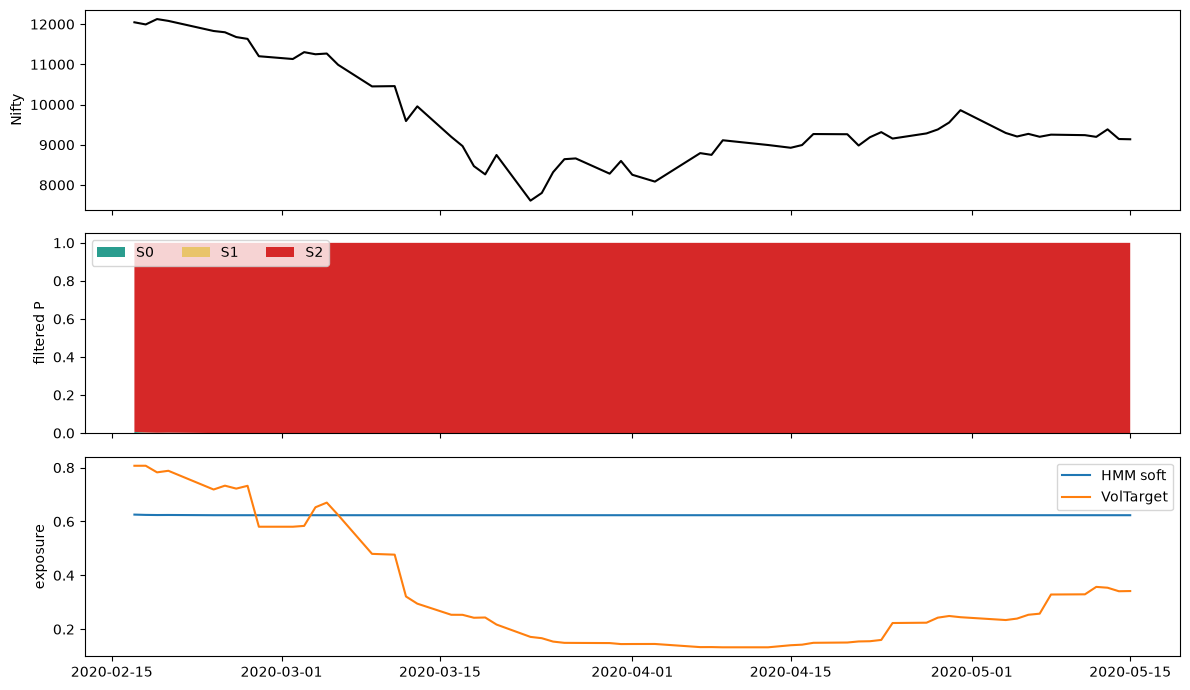

In [9]:
sres = rf.walk_forward(feats, ret, rf.WFConfig(n_states=3, cov_type="diag", warmup_days=252, refit_days=63, n_init=10))
so = ret.reindex(sres.probs.index)
sexpo, srets = run_all(sres.probs, sres.state_vol, so, feats)
print(f"OOS {sres.probs.index.min().date()} -> {sres.probs.index.max().date()}")
display(pd.DataFrame({k: rf.perf(srets[k], sexpo[k], RF) for k in srets}).round(3))

w = slice("2020-02-15", "2020-05-15")
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(df["close"].loc[w], color="black"); ax[0].set_ylabel("Nifty")
ax[1].stackplot(sres.probs.loc[w].index, sres.probs.loc[w].T.values, colors=cols, labels=["S0", "S1", "S2"]); ax[1].set_ylabel("filtered P"); ax[1].legend(ncol=3, loc="upper left")
ax[2].plot(sexpo["HMM soft"].loc[w], label="HMM soft"); ax[2].plot(sexpo["VolTarget (no HMM)"].loc[w], label="VolTarget"); ax[2].set_ylabel("exposure"); ax[2].legend()
plt.tight_layout(); plt.show()

## Conclusions (from the outputs above)

1. **The regimes are persistent and the filter is confident.** Mean entropy is 0.06 and only 1.7% of OOS days have max-probability below 0.6. Expected durations are about 116, 55 and 29 days for calm, middle and stressed. Filtered and smoothed argmax disagree on 6.5% of days, which is the hindsight the old Viterbi labels carried.
2. **The HMM risk overlay did not add value here.** In the primary 3y-warm-up run, HMM-soft has Sharpe 0.21, plain vol-targeting 0.39 and buy & hold 0.53. Block-bootstrap CIs for HMM minus VolTarget (-0.38 to -0.03) and HMM minus Buy & hold (-0.70 to -0.02) are entirely below zero. The HMM lost in 0 of 18 sensitivity cells to either benchmark. The 4-state variants came closest, with Sharpe about 0.33 to 0.36, but still below VolTarget.
3. **Stress test (Covid out of sample, 1y warm-up):** buy & hold had max drawdown -37%, VolTarget -17.5% and HMM-soft -24.6%. The overlay cut the crash, but a trailing-vol rule cut it more, with lower turnover than HMM at the same target.
4. **Why this is not surprising.** The 2022 to 2025 OOS window is a mostly steady bull market, so any de-risking costs return. Every feature the HMM sees is a function of trailing returns and VIX, so its stress state is largely a smoothed version of realised vol. It adds little over the vol rule it is being compared to.
5. **Hard argmax vs soft weighting made almost no difference** because the filter is so confident, so confidence-weighting only matters around the few transition days.

**Limits:** about 3.5 years of OOS, a single bull-market path, a price index with no dividends, and NIFTY.csv starts in 2019, so there is only one crash in the sample. Nothing here proves the HMM is useless in general. It shows it did not beat a one-line vol rule on this data.
